# Log-Loss (Cross-Entropy) for Statistical Classification
## Building and Training Logistic Regression from Scratch

**Workshop:** Statistical Classification and Logistic Regression — In-Class Activity

| | |
|---|---|
| **Author** | _Your name_ |
| **Peer (Team B)** | _Peer's name_ |
| **Repository** | _link to this repo_ |
| **Peer's repository** | _link to peer's repo_ |

---

### Summary

In this notebook I implemented the log-loss (cross-entropy) function myself and used it on the *hours studied → pass/fail* example from the workshop. I built a logistic regression model using only NumPy, and then trained it by making the log-loss as small as possible with gradient descent.

To make sure my code was correct, I checked each part:
- my log-loss gives the same answer as scikit-learn's `log_loss`,
- my gradient formula matches a "brute-force" numerical estimate,
- my trained weights match scikit-learn's `LogisticRegression(penalty=None)`.

### My results

| What I measured | Result |
|---|---|
| Learned weights | $w_0 = -8.535$, $w_1 = 2.968$ |
| Log-loss after training | **0.2321** (compared with 0.6918 for a model that ignores hours, so 66.5% lower) |
| Decision boundary | 2.875 hours |
| Accuracy | 89.47% (17 of 19 students) |
| Matches scikit-learn (`penalty=None`)? | Yes, to two decimal places |

### Contents

1. [The Data](#1.-The-Data)
2. [The Model](#2.-The-Model)
3. [Log-Loss](#3.-Log-Loss)
4. [Training the Model](#4.-Training-the-Model)
5. [Results](#5.-Results)
6. [Is My Result Good?](#6.-Is-My-Result-Good?)
7. [Learning-Rate Experiment](#7.-Learning-Rate-Experiment)
8. [Limitations](#8.-Limitations)
9. [My Talking Points](#9.-My-Talking-Points)
10. [Peer Review Notes](#10.-Peer-Review-Notes)

### How it all fits together

```
hours ──► z = w0 + w1·x ──► p = sigmoid(z) ──► probability of passing
                                                     │
                       actual result (0 or 1) ───────┤
                                                     ▼
                                       log-loss: how wrong was p?
                                                     │
                                                     ▼
                         gradient descent: change w0 and w1 to lower the loss
```

1. The **model** turns hours studied into a probability of passing.
2. **Log-loss** tells me how wrong that probability was.
3. **Gradient descent** uses the log-loss to improve the model, step by step.

So log-loss has two jobs: it is how I **score** the model, and it is what I **train** the model to minimise.

I wrote everything in NumPy so I could see how each formula becomes code. I only used scikit-learn to check my answers.

### Setup

The `verify` function prints ✅ if a check passes and ❌ if it fails. I use it after each step.

In [1]:
import numpy as np
import matplotlib.pyplot as plt
from sklearn.metrics import log_loss as sk_log_loss
from sklearn.linear_model import LogisticRegression


def verify(description, condition):
    # Print ✅ / ❌ for a verification check
    try:
        ok = bool(condition())
    except Exception as e:
        print(f"❌ {description} ({type(e).__name__}: {e})")
        return
    print(f"{'✅' if ok else '❌'} {description}")

---
## 1. The Data

The data has 19 students. For each one I have how many hours they studied (`hours`) and whether they passed (`passed`: **1** = pass, **0** = fail).

I kept the arrays one-dimensional. scikit-learn needs a 2-D table of features, but my own code only has one feature, so 1-D is simpler.

Students: 19   Passed: 9   Pass rate: 0.474


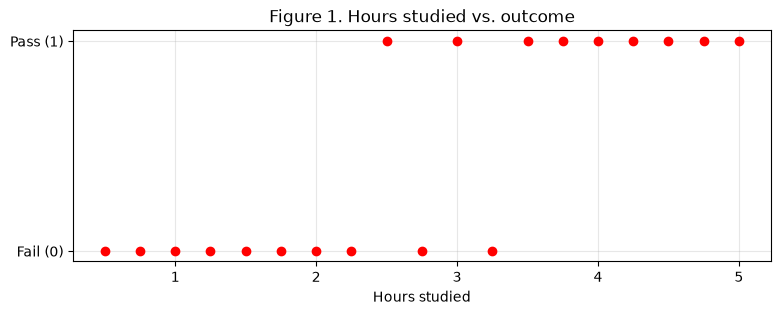

In [2]:
hours = np.array([0.5, 0.75, 1, 1.25, 1.5, 1.75, 2, 2.25, 2.5, 2.75,
                  3, 3.25, 3.5, 3.75, 4, 4.25, 4.5, 4.75, 5])
passed = np.array([0, 0, 0, 0, 0, 0, 0, 0, 1, 0, 1, 0, 1, 1, 1, 1, 1, 1, 1])

n_passed = int(np.sum(passed == 1))
pass_rate = n_passed / len(passed)

print(f"Students: {len(passed)}   Passed: {n_passed}   Pass rate: {pass_rate:.3f}")

plt.figure(figsize=(9, 3))
plt.scatter(hours, passed, color="red", zorder=3)
plt.yticks([0, 1], ["Fail (0)", "Pass (1)"])
plt.xlabel("Hours studied")
plt.title("Figure 1. Hours studied vs. outcome")
plt.grid(alpha=0.3)
plt.show()

In [3]:
verify("n_passed is 9", lambda: n_passed == 9)
verify("pass_rate is 9/19 ≈ 0.474", lambda: np.isclose(pass_rate, 9 / 19))

✅ n_passed is 9
✅ pass_rate is 9/19 ≈ 0.474


### What I noticed

**Can one cut-off ("study more than X hours and you pass") get every student right?**

No. In the middle of the data the results are mixed: the student who studied 2.5 hours passed, 2.75 hours failed, 3.0 hours passed, and 3.25 hours failed. Hours studied isn't the only thing that matters; things like sleep, prior knowledge, or stress also affect the result.

That's why the model predicts a **probability** instead of a hard yes/no. For a student around 2.8 hours, it's more honest to say "about 50/50" than to pretend we know for sure.

---
## 2. The Model

### 2.1 The linear score

$$z = w_0 + w_1 x$$

- $w_0$ is the starting score for a student who studied 0 hours.
- $w_1$ is how much each extra hour adds to the score.
- $z$ is called the **log-odds** of passing. It can be any number, positive or negative. $z = 0$ means a 50/50 chance; a positive $z$ means passing is more likely; a negative $z$ means failing is more likely.

NumPy does maths on every element of an array at once, so the same function works for one student or for all 19.

In [4]:
def linear(x, w0, w1):
    # Log-odds of passing: z = w0 + w1 * x
    return w0 + w1 * x

In [5]:
verify("linear(2, 1, 3) == 7", lambda: linear(2, 1, 3) == 7)
verify("works on arrays", lambda: np.allclose(linear(np.array([0, 1, 2]), -1, 2), [-1, 1, 3]))

✅ linear(2, 1, 3) == 7
✅ works on arrays


### 2.2 The sigmoid

The score $z$ can be any number, but a probability has to be between 0 and 1. The **sigmoid** function squashes $z$ into that range:

$$\sigma(z) = \frac{1}{1 + e^{-z}}$$

- If $z$ is very large, $e^{-z}$ is almost 0, so $\sigma(z)$ is almost 1.
- If $z$ is very negative, $e^{-z}$ is huge, so $\sigma(z)$ is almost 0.
- If $z = 0$, then $\sigma(0) = \frac{1}{2}$.

**Why the sigmoid?**
- A **straight line** can give answers like −0.19 or 1.14, which can't be probabilities.
- A **hard step** (0 below some point, 1 above) gives no probability, and it's flat almost everywhere, so the model wouldn't know which way to improve.
- The **sigmoid** is smooth, stays between 0 and 1, and its slope is easy to calculate. This makes training simple (see Section 4).

In [6]:
def sigmoid(z):
    # Map log-odds to a probability in (0, 1)
    return 1 / (1 + np.exp(-z))

✅ sigmoid(0) == 0.5
✅ sigmoid(10) is close to 1
✅ sigmoid(-10) is close to 0
✅ symmetry: sigmoid(-z) == 1 - sigmoid(z)
✅ works on arrays


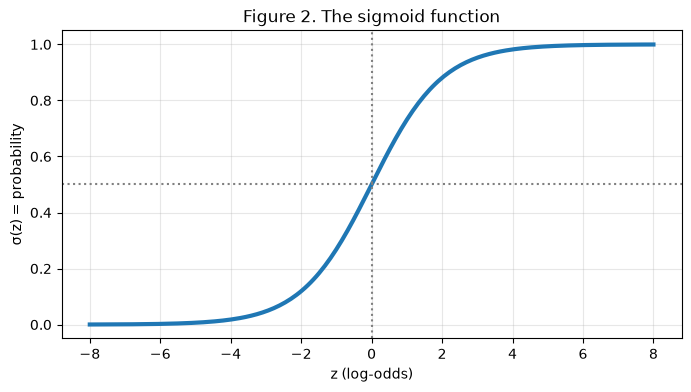

In [7]:
verify("sigmoid(0) == 0.5", lambda: sigmoid(0) == 0.5)
verify("sigmoid(10) is close to 1", lambda: 0.9999 < sigmoid(10) < 1)
verify("sigmoid(-10) is close to 0", lambda: 0 < sigmoid(-10) < 0.0001)
verify("symmetry: sigmoid(-z) == 1 - sigmoid(z)", lambda: np.isclose(sigmoid(-1.7), 1 - sigmoid(1.7)))
verify("works on arrays", lambda: sigmoid(np.zeros(5)).shape == (5,))

z = np.linspace(-8, 8, 200)
plt.figure(figsize=(8, 4))
plt.plot(z, sigmoid(z), lw=3)
plt.axhline(0.5, color="grey", linestyle=":")
plt.axvline(0, color="grey", linestyle=":")
plt.xlabel("z (log-odds)")
plt.ylabel("σ(z) = probability")
plt.title("Figure 2. The sigmoid function")
plt.grid(alpha=0.3)
plt.show()

### What I noticed

**What would a negative $w_1$ mean?**

It would mean that studying more makes passing *less* likely. The S-curve would be flipped: high at 0 hours and dropping as hours go up.

**Where is the decision boundary?**

The sigmoid gives exactly $p = 0.5$ when $z = 0$. So I set the line equal to zero and solved for $x$:

$$w_0 + w_1 x = 0 \implies x = -\frac{w_0}{w_1}$$

---
## 3. Log-Loss

The model gives probabilities, and log-loss tells me how good they are. The idea is simple: **look at the probability the model gave to what actually happened, and take minus its log.**

### 3.1 Loss for one student

$$
\text{loss} =
\begin{cases}
-\log(p), & \text{if the student passed } (y = 1) \\
-\log(1 - p), & \text{if the student failed } (y = 0)
\end{cases}
$$

Here $p$ is the predicted probability of passing.

- The log of a number between 0 and 1 is negative, so the minus sign makes the loss positive.
- If the model gave the right answer 100% probability, the loss is $-\log(1) = 0$.
- If the model gave the right answer almost 0% probability, the loss becomes very large.

| Probability given to what really happened | Loss |
|---|---|
| 0.99 | 0.010 |
| 0.90 | 0.105 |
| 0.50 | 0.693 |
| 0.10 | 2.303 |
| 0.01 | 4.605 |

So being **confident and wrong** is punished much more than being unsure.

In [8]:
def single_loss(y, p):
    # Log-loss for one student (piecewise form)
    if y == 1:
        return -np.log(p)
    else:
        return -np.log(1 - p)

In [9]:
verify("passed, p = 0.9  -> 0.105 (confident and correct)", lambda: np.isclose(single_loss(1, 0.9), 0.10536, atol=1e-4))
verify("failed, p = 0.9  -> 2.303 (confident and wrong)", lambda: np.isclose(single_loss(0, 0.9), 2.30259, atol=1e-4))
verify("passed, p = 0.5  -> 0.693 (uncertain)", lambda: np.isclose(single_loss(1, 0.5), 0.69315, atol=1e-4))
verify("failed, p = 0.05 -> 0.051 (confident and correct)", lambda: np.isclose(single_loss(0, 0.05), 0.05129, atol=1e-4))

✅ passed, p = 0.9  -> 0.105 (confident and correct)
✅ failed, p = 0.9  -> 2.303 (confident and wrong)
✅ passed, p = 0.5  -> 0.693 (uncertain)
✅ failed, p = 0.05 -> 0.051 (confident and correct)


### 3.2 Log-loss for all students at once

Instead of an `if`, one formula handles both cases:

$$\text{loss} = -\left[\,y\log(p) + (1-y)\log(1-p)\,\right]$$

If $y = 1$, the second part becomes 0 and I'm left with $-\log(p)$. If $y = 0$, the first part becomes 0 and I'm left with $-\log(1-p)$. Because there's no `if`, NumPy can do all 19 students in one go. Then I take the average:

$$L = -\frac{1}{N}\sum_{i=1}^{N}\left[\,y_i\log(p_i) + (1-y_i)\log(1-p_i)\,\right]$$

**Avoiding log(0).** If $p$ is exactly 0 or 1, $\log(0)$ is minus infinity and the answer breaks. So I use `np.clip` to keep every probability slightly away from 0 and 1 (between $10^{-15}$ and $1 - 10^{-15}$).

In [10]:
def log_loss(y_true, y_prob, eps=1e-15):
    # Average binary cross-entropy
    y_prob = np.clip(y_prob, eps, 1 - eps)
    losses = -(y_true * np.log(y_prob) + (1 - y_true) * np.log(1 - y_prob))
    return np.mean(losses)

In [11]:
p_test = np.array([0.1, 0.4, 0.35, 0.8, 0.9])
y_test = np.array([0, 0, 1, 1, 1])

verify("every p = 0.5 gives ln 2 ≈ 0.6931 (uninformed model)",
       lambda: np.isclose(log_loss(passed, np.full(19, 0.5)), np.log(2)))
verify("agrees with single_loss averaged in a loop",
       lambda: np.isclose(log_loss(y_test, p_test), np.mean([single_loss(y, p) for y, p in zip(y_test, p_test)])))
verify("matches sklearn.metrics.log_loss",
       lambda: np.isclose(log_loss(y_test, p_test), sk_log_loss(y_test, p_test)))
verify("clipping: p = 0 and p = 1 give a finite loss",
       lambda: np.isfinite(log_loss(np.array([1, 0]), np.array([0.0, 1.0]))))

✅ every p = 0.5 gives ln 2 ≈ 0.6931 (uninformed model)
✅ agrees with single_loss averaged in a loop
✅ matches sklearn.metrics.log_loss
✅ clipping: p = 0 and p = 1 give a finite loss


Everything after this point uses `log_loss`, so I checked it against scikit-learn before building anything on top of it.

### What I noticed

**Why does a confident wrong answer cost so much more than an unsure one?**

The loss only looks at the probability given to the true result. Say a student failed:
- If my model said 55% pass, it gave 45% to the truth. The loss is $-\log(0.45) \approx 0.80$, which is not much worse than being 50/50 (0.693).
- If my model said 99% pass, it gave only 1% to the truth. The loss jumps to $-\log(0.01) = 4.605$.

**Why not just use accuracy?**

Accuracy only checks if the answer is on the right side of 0.5. It treats 0.51 and 0.99 the same, even though 0.99 is much more confident. Also, accuracy only changes in jumps, so it can't tell gradient descent which direction to move.

**What happens without `np.clip`?**

If a probability is exactly 0 or 1, `np.log(0)` gives minus infinity. Then $0 \times (-\infty)$ gives `nan` ("not a number"), and the whole loss and training break.

---
## 4. Training the Model

Now I want the values of $w_0$ and $w_1$ that make the log-loss as small as possible.

For linear regression there's a formula for the best weights. For logistic regression there isn't one, because the weights are inside the sigmoid. So I find them step by step with **gradient descent**:

$$w \leftarrow w - \eta\,\frac{\partial L}{\partial w}$$

The gradient tells me which direction makes the loss go **up**, so I move the opposite way. $\eta$ (the learning rate) is the size of each step.

### 4.1 The gradient

Using the chain rule for one student:

$$
\frac{\partial\,\text{loss}}{\partial w_1}
= \underbrace{\frac{p - y}{p(1-p)}}_{\text{loss vs. } p}
\;\cdot\; \underbrace{p(1-p)}_{\text{slope of the sigmoid}}
\;\cdot\; \underbrace{x}_{z \text{ vs. } w_1}
= (p - y)\,x
$$

The $p(1-p)$ parts cancel out, which leaves a very simple answer. For $w_0$ the last part is 1 instead of $x$. Averaged over all students:

$$\frac{\partial L}{\partial w_0} = \text{mean}(p - y) \qquad\qquad \frac{\partial L}{\partial w_1} = \text{mean}\big((p - y)\cdot x\big)$$

$(p - y)$ is just **how wrong** the model was for each student. So the students the model gets most wrong push the weights the most.

### Why log-loss and not mean squared error (MSE)?

With MSE, the $p(1-p)$ part does **not** cancel. When the model is very wrong and very confident, $p(1-p)$ is tiny, so the model barely learns from its worst mistakes:

| Loss | Gradient when $p = 0.01$ but the student passed |
|---|---|
| MSE | about −0.020 |
| Log-loss | −0.99 (about 50 times stronger) |

Log-loss also has only one lowest point (it's shaped like a bowl), so gradient descent can't get stuck in the wrong place.

In [12]:
def gradients(x, y, w0, w1):
    # Gradients of the average log-loss with respect to w0 and w1
    p = sigmoid(linear(x, w0, w1))
    error = p - y
    grad_w0 = np.mean(error)
    grad_w1 = np.mean(error * x)
    return grad_w0, grad_w1

**Checking my gradient.** A derivative means "how much does the output change if I nudge the input a tiny bit?" So I can estimate the gradient without calculus, by nudging each weight a tiny amount $h$ and seeing how the loss changes:

$$\frac{\partial L}{\partial w_1} \approx \frac{L(w_1 + h) - L(w_1 - h)}{2h}$$

If my formula matches this estimate at several different points, my gradient is correct.

In [13]:
def numerical_gradients(x, y, w0, w1, h=1e-6):
    # Central-difference estimate of the gradient
    L = lambda a, b: log_loss(y, sigmoid(linear(x, a, b)))
    d_w0 = (L(w0 + h, w1) - L(w0 - h, w1)) / (2 * h)
    d_w1 = (L(w0, w1 + h) - L(w0, w1 - h)) / (2 * h)
    return d_w0, d_w1


for a, b in [(0.0, 0.0), (-4.0, 1.5), (2.0, -1.0), (-8.5, 3.0), (1.0, 0.5)]:
    verify(f"analytical gradient matches numerical estimate at w0={a:.2f}, w1={b:.2f}",
           lambda: np.allclose(gradients(hours, passed, a, b), numerical_gradients(hours, passed, a, b), atol=1e-6))

✅ analytical gradient matches numerical estimate at w0=0.00, w1=0.00
✅ analytical gradient matches numerical estimate at w0=-4.00, w1=1.50
✅ analytical gradient matches numerical estimate at w0=2.00, w1=-1.00
✅ analytical gradient matches numerical estimate at w0=-8.50, w1=3.00
✅ analytical gradient matches numerical estimate at w0=1.00, w1=0.50


### 4.2 The training loop

I start with $w_0 = w_1 = 0$. That gives every student $p = 0.5$, which is like the model knowing nothing yet. Because the loss is bowl-shaped, the starting point doesn't change where it ends up.

Each step: calculate the probabilities, record the loss, calculate the gradient, then move the weights a small step downhill.

In [14]:
def train(x, y, learning_rate=0.5, n_iterations=5000):
    # Batch gradient descent on the average log-loss
    w0, w1 = 0.0, 0.0
    history = []
    for _ in range(n_iterations):
        p = sigmoid(linear(x, w0, w1))
        history.append(log_loss(y, p))
        grad_w0, grad_w1 = gradients(x, y, w0, w1)
        w0 -= learning_rate * grad_w0
        w1 -= learning_rate * grad_w1
    return w0, w1, history


w0, w1, loss_history = train(hours, passed)
print(f"w0 = {w0:.4f}, w1 = {w1:.4f}")
print(f"Log-loss: {loss_history[0]:.4f} (start) -> {loss_history[-1]:.4f} (end)")

w0 = -8.5348, w1 = 2.9684
Log-loss: 0.6931 (start) -> 0.2321 (end)


✅ starts at ln 2 ≈ 0.6931
✅ loss never increases
✅ final loss ≈ 0.2321


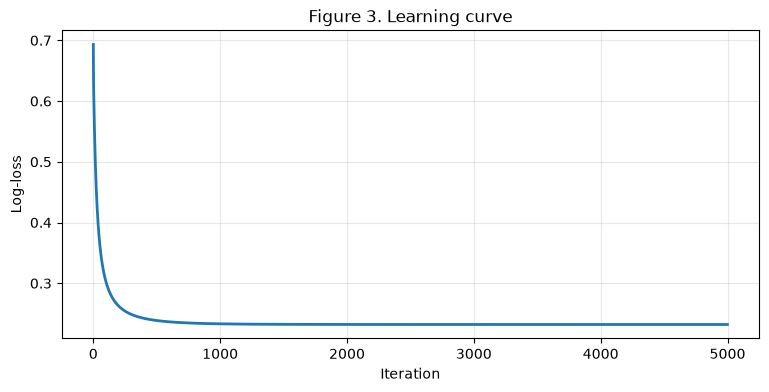

In [15]:
verify("starts at ln 2 ≈ 0.6931", lambda: np.isclose(loss_history[0], np.log(2)))
verify("loss never increases", lambda: np.all(np.diff(loss_history) <= 1e-12))
verify("final loss ≈ 0.2321", lambda: np.isclose(loss_history[-1], 0.2321, atol=1e-3))

plt.figure(figsize=(9, 4))
plt.plot(loss_history, lw=2)
plt.xlabel("Iteration")
plt.ylabel("Log-loss")
plt.title("Figure 3. Learning curve")
plt.grid(alpha=0.3)
plt.show()

### What I noticed

**Why does the learning curve drop fast at first and then flatten out?**

At the start, every student gets $p = 0.5$, so the errors $(p - y)$ are big. Big errors give big gradients, so the weights change a lot and the loss falls quickly. As the model improves, the errors get smaller and start to balance each other out, so the gradient gets close to zero. The steps become tiny and the curve flattens at about 0.2321.

**Why is the gradient just $(p - y)\,x$, and why does that make sense?**

When I use the chain rule, the slope of the sigmoid $p(1-p)$ cancels with the bottom of the log-loss derivative. What's left is the error times the hours. This makes sense to me: small mistakes cause small changes, and big mistakes cause big corrections.

---
## 5. Results

### 5.1 Decision boundary and accuracy

In [16]:
boundary = -w0 / w1
probabilities = sigmoid(linear(hours, w0, w1))
predictions = (probabilities >= 0.5).astype(int)
accuracy = np.mean(predictions == passed)

print(f"Decision boundary: {boundary:.3f} hours")
print(f"Training accuracy: {accuracy:.2%} ({np.sum(predictions == passed)} of {len(passed)})")

Decision boundary: 2.875 hours
Training accuracy: 89.47% (17 of 19)


✅ boundary ≈ 2.875 hours
✅ predictions are 0/1 for all 19 students
✅ accuracy = 17/19 ≈ 89.47%


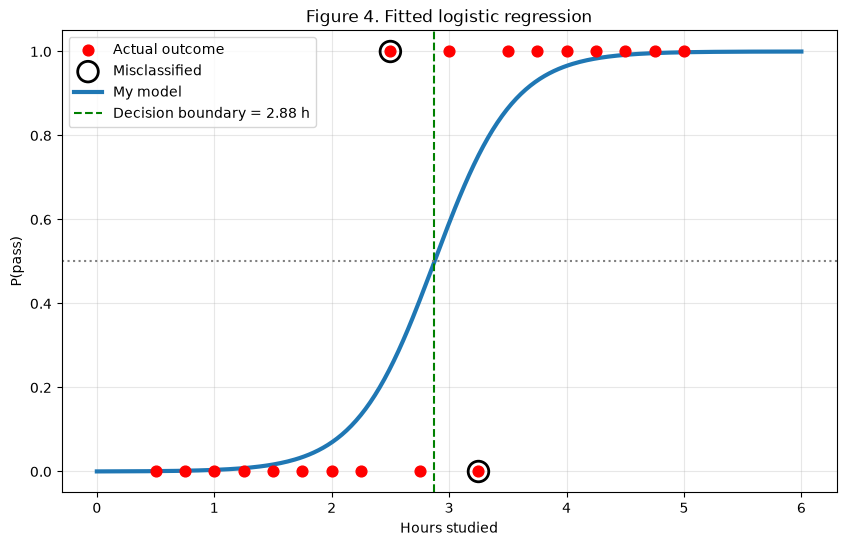

In [17]:
verify("boundary ≈ 2.875 hours", lambda: np.isclose(boundary, 2.875, atol=0.01))
verify("predictions are 0/1 for all 19 students",
       lambda: predictions.shape == (19,) and set(np.unique(predictions)) <= {0, 1})
verify("accuracy = 17/19 ≈ 89.47%", lambda: np.isclose(accuracy, 17 / 19))

x_grid = np.linspace(0, 6, 300)
wrong = predictions != passed

plt.figure(figsize=(10, 6))
plt.scatter(hours, passed, color="red", zorder=3, s=60, label="Actual outcome")
plt.scatter(hours[wrong], passed[wrong], facecolors="none", edgecolors="black", s=220,
            linewidths=2, zorder=4, label="Misclassified")
plt.plot(x_grid, sigmoid(linear(x_grid, w0, w1)), lw=3, label="My model")
plt.axvline(boundary, color="green", linestyle="--", label=f"Decision boundary = {boundary:.2f} h")
plt.axhline(0.5, color="grey", linestyle=":")
plt.xlabel("Hours studied")
plt.ylabel("P(pass)")
plt.title("Figure 4. Fitted logistic regression")
plt.legend()
plt.grid(alpha=0.3)
plt.show()

**Table 1.** The prediction and loss for every student.

In [18]:
print(f"{'Hours':>5} | {'y':>1} | {'P(pass)':>7} | {'Loss':>5}")
print("-" * 32)
for h, y, p in zip(hours, passed, probabilities):
    flag = "  misclassified" if (p >= 0.5) != y else ""
    print(f"{h:>5} | {y:>1} | {p:7.3f} | {single_loss(y, p):5.3f}{flag}")

Hours | y | P(pass) |  Loss
--------------------------------
  0.5 | 0 |   0.001 | 0.001
 0.75 | 0 |   0.002 | 0.002
  1.0 | 0 |   0.004 | 0.004
 1.25 | 0 |   0.008 | 0.008
  1.5 | 0 |   0.017 | 0.017
 1.75 | 0 |   0.034 | 0.035
  2.0 | 0 |   0.069 | 0.072
 2.25 | 0 |   0.135 | 0.145
  2.5 | 1 |   0.247 | 1.398  misclassified
 2.75 | 0 |   0.408 | 0.525
  3.0 | 1 |   0.592 | 0.525
 3.25 | 0 |   0.753 | 1.397  misclassified
  3.5 | 1 |   0.865 | 0.145
 3.75 | 1 |   0.931 | 0.072
  4.0 | 1 |   0.966 | 0.035
 4.25 | 1 |   0.983 | 0.017
  4.5 | 1 |   0.992 | 0.008
 4.75 | 1 |   0.996 | 0.004
  5.0 | 1 |   0.998 | 0.002


### 5.2 Predicting new students

I made the "Pass"/"Fail" label come straight from the probability, instead of typing it by hand, so the label can never disagree with the model.

In [19]:
def predict(h):
    # Return (probability of passing, "Pass" or "Fail")
    prob = float(sigmoid(linear(h, w0, w1)))
    label = "Pass" if prob >= 0.5 else "Fail"
    return prob, label


verify("2.6 h -> Fail", lambda: predict(2.6)[1] == "Fail")
verify("2.9 h -> Pass", lambda: predict(2.9)[1] == "Pass")
verify("probability lies in (0, 1)", lambda: 0 < predict(4)[0] < 1)

for h in [1.0, 2.6, 2.9, 4.5]:
    p, label = predict(h)
    print(f"{h} h -> P(pass) = {p:.3f} -> {label}")

✅ 2.6 h -> Fail
✅ 2.9 h -> Pass
✅ probability lies in (0, 1)
1.0 h -> P(pass) = 0.004 -> Fail
2.6 h -> P(pass) = 0.306 -> Fail
2.9 h -> P(pass) = 0.518 -> Pass
4.5 h -> P(pass) = 0.992 -> Pass


### What I noticed

**Which students are wrong, and why can't any cut-off fix both?**

The boundary is at 2.875 hours. The two students my model gets wrong are:
- the student who studied **2.5 hours and passed** (the model says fail), and
- the student who studied **3.25 hours and failed** (the model says pass).

No cut-off can fix both. Moving it below 2.5 would make the failures at 2.75 and 3.25 wrong. Moving it above 3.25 would make the passes at 2.5 and 3.0 wrong.

**Accuracy stayed at 89.47%, but the log-loss kept going down. What was improving?**

Once the boundary settled near 2.875 hours, the pass/fail labels stopped changing, so accuracy stayed the same. But training kept making the S-curve steeper, so clear passes (like 4.5 hours) got closer to 1 and clear failures (like 1.0 hour) got closer to 0. The model became more confident about the students it was already getting right.

---
## 6. Is My Result Good?

A log-loss of 0.2321 doesn't mean much on its own, so I compared it with two things: a very simple baseline, and scikit-learn.

### 6.1 Baseline

The baseline ignores hours completely and gives every student the same probability: the overall pass rate (9 out of 19).

In [20]:
baseline_loss = log_loss(passed, np.full(len(passed), pass_rate))

verify("baseline log-loss ≈ 0.6918", lambda: np.isclose(baseline_loss, 0.6918, atol=1e-3))
print(f"Baseline: {baseline_loss:.4f}   Model: {loss_history[-1]:.4f}   "
      f"Reduction: {1 - loss_history[-1] / baseline_loss:.1%}")

✅ baseline log-loss ≈ 0.6918
Baseline: 0.6918   Model: 0.2321   Reduction: 66.5%


### 6.2 Comparing with scikit-learn

- `LogisticRegression(penalty=None)` minimises plain log-loss, just like my code, so its weights should match mine.
- `LogisticRegression()` (the default, used in the workshop notebook) adds **L2 regularisation**, a penalty that keeps the weights small. This makes the S-curve flatter and the training loss a bit higher.

In [21]:
X = hours.reshape(-1, 1)
sk_plain = LogisticRegression(penalty=None, max_iter=1000).fit(X, passed)
sk_default = LogisticRegression().fit(X, passed)

print(f"{'Model':<28} | {'w0':>7} | {'w1':>6} | {'Log-loss':>8}")
print("-" * 58)
print(f"{'My implementation':<28} | {w0:7.3f} | {w1:6.3f} | {loss_history[-1]:8.4f}")
for name, m in [("sklearn, penalty=None", sk_plain), ("sklearn default (L2, C=1)", sk_default)]:
    print(f"{name:<28} | {m.intercept_[0]:7.3f} | {m.coef_[0][0]:6.3f} | "
          f"{sk_log_loss(passed, m.predict_proba(X)[:, 1]):8.4f}")

verify("weights match sklearn's unregularised model",
       lambda: np.allclose([w0, w1], [sk_plain.intercept_[0], sk_plain.coef_[0][0]], atol=0.05))

Model                        |      w0 |     w1 | Log-loss
----------------------------------------------------------
My implementation            |  -8.535 |  2.968 |   0.2321
sklearn, penalty=None        |  -8.540 |  2.970 |   0.2321
sklearn default (L2, C=1)    |  -4.517 |  1.568 |   0.2754
✅ weights match sklearn's unregularised model


/Users/namy/.cache/uv/archive-v0/fzNNgXtYrAgl6mju/lib/python3.14/site-packages/sklearn/linear_model/_logistic.py:1381: FutureWarning: 'penalty' was deprecated in version 1.8 and will be removed in 1.10. To avoid this warning, leave 'penalty' set to its default value and use 'l1_ratio' or 'C' instead. Use l1_ratio=0 instead of penalty='l2', l1_ratio=1 instead of penalty='l1', l1_ratio set to a float between 0 and 1 instead of penalty='elasticnet', and C=np.inf instead of penalty=None.
  warnings.warn(


### What I noticed

**Does knowing the hours actually help?**

Yes. Guessing the pass rate for everyone gives a log-loss of 0.6918, which is about the same as flipping a coin (0.6931). Using hours brings it down to 0.2321, which is 66.5% lower. So hours studied really does help predict the result.

**My loss (0.232) is lower than the workshop's scikit-learn model (0.275). Does that make mine better?**

Not necessarily. My weights ($w_0 \approx -8.53$, $w_1 \approx 2.97$) match `LogisticRegression(penalty=None)`, which only tries to fit the training data. The default scikit-learn model keeps the weights smaller ($w_0 \approx -4.52$, $w_1 \approx 1.57$), so it fits the training data a bit less well. With only 19 students, keeping the weights small helps stop the model from being overconfident on new students it hasn't seen.

---
## 7. Learning-Rate Experiment

I trained the same model with four different learning rates for 2,000 steps each.

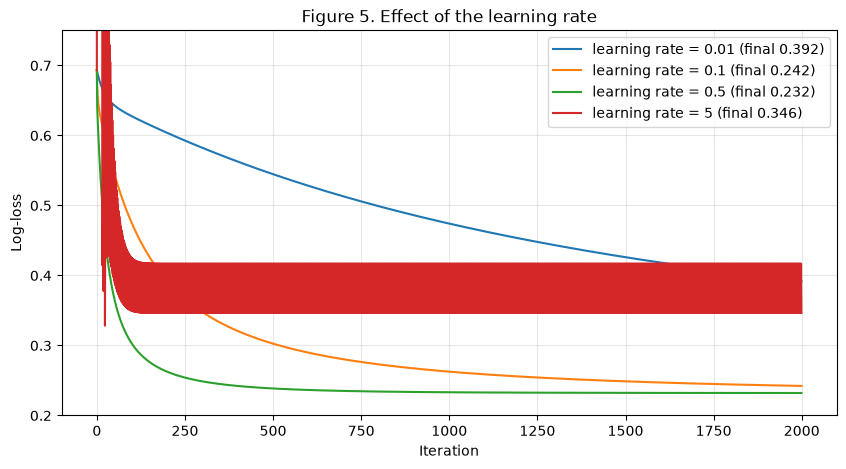

In [22]:
plt.figure(figsize=(10, 5))
for lr in [0.01, 0.1, 0.5, 5]:
    _, _, hist = train(hours, passed, learning_rate=lr, n_iterations=2000)
    plt.plot(hist, label=f"learning rate = {lr} (final {hist[-1]:.3f})")
plt.ylim(0.2, 0.75)
plt.xlabel("Iteration")
plt.ylabel("Log-loss")
plt.title("Figure 5. Effect of the learning rate")
plt.legend()
plt.grid(alpha=0.3)
plt.show()

### What I noticed

**What goes wrong with a learning rate of 0.01, and with 5?**

- **0.01 is too small.** The steps are tiny, so learning is slow. After 2,000 steps the loss is still above 0.35.
- **5 is too big.** Each step jumps over the bottom of the bowl, so the loss bounces up and down the whole time and never settles. It ends at about 0.35, far from the best value of 0.232.

**How would I pick a learning rate for a new problem?**

I would try a range of values (for example 0.001, 0.01, 0.1, 0.5, 1.0) for a few hundred steps, plot the loss curves, and pick the biggest one where the loss goes down smoothly without bouncing.

---
## 8. Limitations

- **I tested on the same data I trained on.** All 19 students were used for training, and I measured the results on the same 19. So my log-loss (0.2321) and accuracy (89.47%) are probably better than they would be on new students.
- **Only one feature.** Passing depends on more than hours studied, for example past grades, attendance, or sleep. That's why students between 2.5 and 3.25 hours have mixed results.
- **The 0.5 cut-off.** Using 0.5 assumes that both kinds of mistakes are equally bad. If this model were used to find students who need tutoring, missing a student who will fail is worse than helping one who would have passed anyway. In that case I would only say "Pass" when the probability is higher, for example 0.75 or 0.80.

---
## 9. My Talking Points

### 1. Why log-loss and not accuracy or MSE

**My point:** Log-loss is a better choice because it punishes confident mistakes heavily, and it keeps giving a strong signal to learn from.

**Evidence:** In Section 3, giving only 1% probability to the true result costs 4.605, while being unsure (50%) costs 0.693. In Section 4, when the model is very wrong ($p = 0.01$ but the student passed), the log-loss gradient is −0.99, about 50 times stronger than MSE's −0.020.

**Why it matters:** With MSE, the model would hardly learn from its worst mistakes. Log-loss keeps learning strong and has only one lowest point to find.

### 2. Checking my own code

**My point:** Before trusting my results, I checked my code in three different ways.

**Evidence:** My `log_loss` gives the same answer as scikit-learn's. My gradient formula $(p - y)\,x$ matches the numerical estimate at five different points. My trained model brings the loss down from the baseline of 0.6918 to 0.2321 (66.5% lower).

**Why it matters:** A mistake in the gradient can still make the loss go down, but end up at the wrong answer. These checks show my maths is right and that the model actually learned something useful.

### 3. Why my loss is lower than scikit-learn's default

**My point:** Having a lower training loss than the workshop's model doesn't automatically mean my model is better.

**Evidence:** My model ends with $w_0 = -8.53$, $w_1 = 2.97$ and a loss of 0.2321, the same as `LogisticRegression(penalty=None)`. The default `LogisticRegression()` uses L2 regularisation, keeps the weights smaller ($w_0 = -4.52$, $w_1 = 1.57$), and has a loss of 0.2754.

**Why it matters:** With only 19 students, letting the weights grow very large makes the model overconfident. Regularisation gives up a little accuracy on the training data so that the model behaves better on new students.

---
## 10. Peer Review Notes

### 10.1 Reviewing my peer's code

| Question | Notes |
|---|---|
| Does their notebook run from top to bottom (*Restart & Run All*)? | |
| Does their log-loss match scikit-learn? | |
| Do they handle $\log(0)$ (clipping)? | |
| Do they explain the formulas in markdown, or only show code? | |
| Do they train the model, or only calculate the loss? | |
| Do they compare with a baseline or with scikit-learn? | |

**My questions for my peer**
1. _..._
2. _..._

### 10.2 Questions my peer asked me
1. _..._
2. _..._

### 10.3 My notes on my peer's talking points

| Talking point | What was clear | What I would question or add |
|---|---|---|
| 1 | | |
| 2 | | |
| 3 | | |

### 10.4 What we learned from the exchange
_..._